# 01 · Data Understanding

**Project:** Wearable Exercise Physiology Analytics. Physiological responses to aerobic exercise,
anaerobic exercise and acute stress.
**Dataset:** *Wearable Device Dataset from Induced Stress and Structured Exercise Sessions*, PhysioNet v1.0.1,
DOI [10.13026/he0v-tf17](https://doi.org/10.13026/he0v-tf17). Companion paper: Hongn et al., *Scientific Data* 12, 2025
([10.1038/s41597-025-04845-9](https://doi.org/10.1038/s41597-025-04845-9)).

This notebook is **descriptive only**. It inventories the files, participants, protocols, sampling rates,
synchronisation, missing data and signal quality. **Nothing is filtered, removed or modelled here.**
Findings are written up in `docs/data_dictionary.md`, `docs/protocol_summary.md` and `docs/phase1_report.md`.

Guiding distinction: accelerometry tells us mainly about **movement**. HR, BVP/IBI, EDA and skin temperature
describe the **physiological state**. Both are needed, and they must not be confused.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.empatica import (DATASET_ROOT, RAW_ROOT, DOCUMENTED_FS, UNITS, list_sessions,
                               load_session, read_subject_info, read_stress_levels, FLAG_MEANING)
from src.data.inventory import build_inventory
from src.data.protocol import PROTOCOLS, MANUAL_MAPS, segment_session, expected_n_tags
from src.data.issues import issues_table
from src.visualization import plots as P

P.set_style()
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"; INTERIM.mkdir(parents=True, exist_ok=True)

## 1 · Provenance and integrity

All 707 data and metadata files were checked against the official `SHA256SUMS.txt` of PhysioNet v1.0.1.
The signal files were obtained from the authors' Zenodo mirror because PhysioNet throttled the download.
Every file matched the v1.0.1 checksum byte-for-byte; three Zenodo folder names (`S03_`, `S07_`, `S06_`)
were renamed to their PhysioNet names. Licence: ODC Attribution (ODC-By).

In [2]:
import hashlib
sums = pd.read_csv(RAW_ROOT / "SHA256SUMS.txt", sep=" ", header=None, names=["sha256", "path"])
sums = sums[~sums.path.str.endswith(".ipynb")]
ok = [hashlib.sha256((RAW_ROOT / p).read_bytes()).hexdigest() == h for h, p in zip(sums.sha256, sums.path)]
print(f"{sum(ok)} / {len(ok)} files match the PhysioNet v1.0.1 SHA-256 manifest")

707 / 707 files match the PhysioNet v1.0.1 SHA-256 manifest


## 2 · Folder structure

```
data/raw/
├── README.txt, LICENSE.txt, SHA256SUMS.txt
├── Data_Dictionary.csv          # signal codes, fs, units (authors)
├── subject-info.csv             # demographics + protocol participation + footnote flags
├── Stress_Level_v1.csv / _v2.csv# self-reported stress per stress-protocol block
├── data_constraints.txt         # authors' list of known problems
└── Wearable_Dataset/
    ├── STRESS/    S01..S18, f01..f13, f14_a, f14_b, f15..f18
    ├── AEROBIC/   S01..S18 (no S12; S11 split into _a/_b), f01..f13
    └── ANAEROBIC/ S01..S18 (S16 split into _a/_b), f01..f13
        └── <session>/ ACC.csv BVP.csv EDA.csv HR.csv IBI.csv TEMP.csv tags.csv
```
A *session* is one folder (one recording). A *participant* can have several sessions: one per protocol,
and two when the Bluetooth connection dropped (`_a`/`_b`).

In [3]:
sessions, quality, ibi, tags, sync = build_inventory()
tags["expected_n_tags"] = [expected_n_tags(c, s) for c, s in zip(tags.condition, tags.session_id)]
for name, df in dict(sessions=sessions, quality=quality, ibi=ibi, tags=tags, sync=sync).items():
    df.to_csv(INTERIM / f"inventory_{name}.csv", index=False)

summary = (sessions.groupby(["condition", "cohort"])
           .agg(sessions=("session_id", "size"), participants=("subject_id", "nunique"),
                split_sessions=("is_split", "sum")))
summary

sessions  participants  split_sessions
condition cohort                                        
AEROBIC   V1            18            17               2
          V2            13            13               0
ANAEROBIC V1            19            18               2
          V2            13            13               0
STRESS    V1            18            18               0
          V2            19            18               2

In [4]:
file_presence = sessions.filter(like="has_").rename(columns=lambda c: c[4:])
missing = sessions.loc[~file_presence.all(axis=1), ["condition", "session_id"]].copy()
missing["missing_or_empty_files"] = file_presence[~file_presence.all(axis=1)].apply(
    lambda r: ", ".join(r.index[~r]), axis=1)
print(f"{len(sessions)} sessions, {file_presence.size} expected files, "
      f"{(~file_presence).sum().sum()} missing/empty")
missing

100 sessions, 700 expected files, 2 missing/empty


,condition,session_id,missing_or_empty_files
13,STRESS,f14_a,tags
81,ANAEROBIC,S01,IBI


## 3 · Participants

`subject-info.csv` encodes participation as `Yes` / `-` with footnote asterisks:
`*` wrong wristband placement · `**` connection loss · `***` protocol not completed · `****` files with constraints.

In [5]:
info = read_subject_info()
info["cohort"] = np.where(info.subject_id.str.startswith("S"), "V1", "V2")
demo = (info.groupby("cohort")
        .agg(n=("subject_id", "size"),
             female=("Gender", lambda g: (g.str.strip() == "f").sum()),
             age_mean=("Age", "mean"), age_min=("Age", "min"), age_max=("Age", "max"),
             bmi_mean=("bmi", "mean"),
             trains_regularly=("Does physical activity regularly?", lambda g: (g == "Yes").sum()),
             demographics_missing=("Age", lambda a: a.isna().sum()),
             stress=("stress_done", "sum"), aerobic=("aerobic_done", "sum"), anaerobic=("anaerobic_done", "sum"))
        .round(1))
demo

,n,female,age_mean,age_min,age_max,bmi_mean,trains_regularly,demographics_missing,stress,aerobic,anaerobic
cohort,,,,,,,,,,,
V1,18,0,20.3,18.0,22.0,23.5,17,0,18,17,18
V2,18,17,25.1,21.0,31.0,23.9,4,5,18,13,13


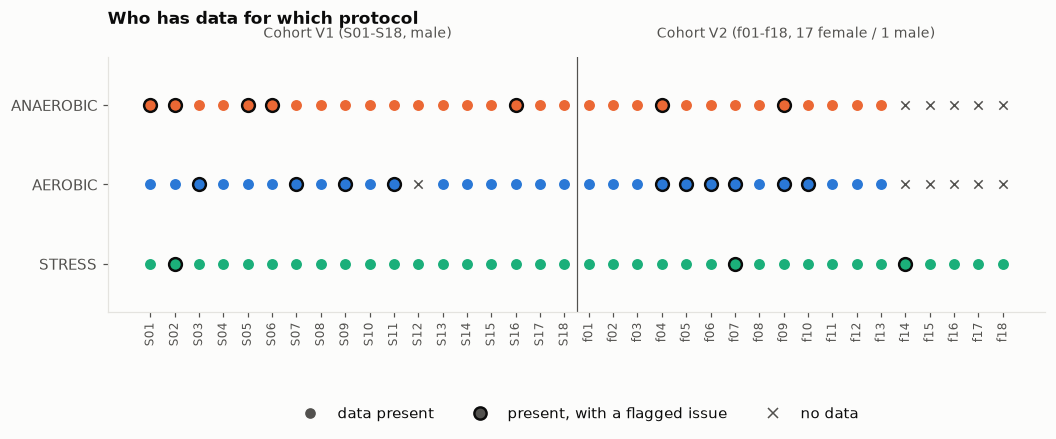

Participants with all three protocols: 30 (V1: 17, V2: 13)
Stress only (no exercise, no demographics): ['f14', 'f15', 'f16', 'f17', 'f18']


In [6]:
flag_cols = {"STRESS": "stress_flag", "AEROBIC": "aerobic_flag", "ANAEROBIC": "anaerobic_flag"}
flagged = {(r.subject_id, c) for r in info.itertuples() for c, col in flag_cols.items() if getattr(r, col) > 0}
# add issues discovered in Phase 1
iss = issues_table()
for r in iss.itertuples():
    for sid in str(r.session_id).replace("/", ",").split(","):
        sid = sid.strip().split("_")[0]
        for c in str(r.condition).split(","):
            if sid.startswith(("S", "f")) and c in flag_cols:
                flagged.add((sid, c))
fig = P.participation_matrix(info, sessions, flagged)
P.save(fig, "01_participation_matrix"); plt.show()

both = info[info.stress_done & info.aerobic_done & info.anaerobic_done]
print(f"Participants with all three protocols: {len(both)} "
      f"(V1: {(both.cohort=='V1').sum()}, V2: {(both.cohort=='V2').sum()})")
print("Stress only (no exercise, no demographics):", info[info.stress_done & ~info.aerobic_done & ~info.anaerobic_done].subject_id.tolist())

**Key structural fact:** the dataset is mostly **within-subject**. 30 participants have all three protocols,
so STRESS vs AEROBIC vs ANAEROBIC can be compared *within the same person*. But cohort is perfectly confounded
with sex and protocol version: V1 is 18 men on protocol V1, V2 is 17 women and 1 man on protocol V2. Any
V1-vs-V2 difference is uninterpretable as a sex effect.

## 4 · Signal inventory and sampling rates (verified from file headers, not assumed)

In [7]:
fs = (quality.groupby("signal")
      .agg(fs_in_headers=("fs_header", lambda s: sorted(s.unique())),
           all_match_documentation=("fs_matches_doc", "all"),
           sessions=("present", "sum"),
           median_duration_min=("duration_min", "median"))
      .assign(documented_fs=lambda d: d.index.map(DOCUMENTED_FS), unit=lambda d: d.index.map(UNITS)))
fs.loc["IBI"] = [["event-based"], True, int(ibi.ibi_present.sum()), np.nan, np.nan, UNITS["IBI"]]
fs

,fs_in_headers,all_match_documentation,sessions,median_duration_min,documented_fs,unit
signal,,,,,,
ACC,[32.0],True,100,33.962500,32.0,1/64 g (range +/-2 g)
BVP,[64.0],True,100,33.961068,64.0,arbitrary PPG units (no physical unit)
EDA,[4.0],True,100,33.950000,4.0,microsiemens (uS)
HR,[1.0],True,100,33.800000,1.0,"beats per minute (10-s moving average, Empatic..."
TEMP,[4.0],True,100,33.950000,4.0,degrees Celsius
IBI,[event-based],True,99,NaN,NaN,seconds


In [8]:
# IBI values are quantised to the 64 Hz BVP sample grid (1/64 s = 15.6 ms)
print("IBI values on a 1/64-s grid in all non-empty files:", bool(ibi.loc[ibi.ibi_present, "ibi_multiple_of_1_64s"].all()))

IBI values on a 1/64-s grid in all non-empty files: True


## 5 · Recording durations and synchronisation
All five uniformly-sampled files of a session share the same start timestamp, **except HR, which starts
exactly 10 s later** in every session (Empatica's 10-s averaging window). Ends differ by a few seconds
because each file is truncated independently.

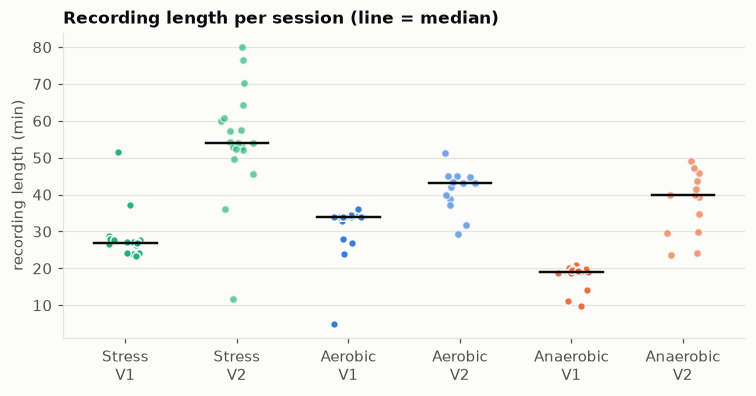

count  mean   std   min   25%   50%   75%   max
condition cohort                                                 
AEROBIC   V1       18.0  31.2   7.3   5.0  33.2  34.0  34.0  36.2
          V2       13.0  41.2   5.9  29.2  38.8  43.2  44.9  51.3
ANAEROBIC V1       19.0  18.2   3.0   9.8  18.8  19.1  19.5  21.0
          V2       13.0  37.6   8.5  23.6  29.8  39.9  43.6  49.0
STRESS    V1       18.0  28.2   6.6  23.4  24.7  27.0  27.7  51.6
          V2       19.0  54.9  14.6  11.7  52.2  54.0  60.4  80.2

In [9]:
dur = quality[quality.signal == "EDA"].merge(sessions[["condition", "session_id", "cohort"]])
fig = P.strip_by_condition(dur, "duration_min", "recording length (min)",
                           "Recording length per session (line = median)")
P.save(fig, "01_recording_durations"); plt.show()
dur.groupby(["condition", "cohort"]).duration_min.describe().round(1)

In [10]:
offs = sync.filter(like="offset_s").drop(columns="IBI_start_offset_s").describe().T[["mean", "min", "max"]].round(2)
print(offs)
print("\nMax spread of end times among ACC/BVP/EDA/TEMP (s):", sync.max_raw_end_spread_s.describe()[["50%", "max"]].round(2).to_dict())
print("IBI start differs from the other signals in:", sync.loc[sync.IBI_start_offset_s.abs() > 1, ["condition", "session_id"]].values.tolist())

                      mean    min    max
ACC_start_offset_s    0.00   0.00   0.00
ACC_end_offset_s      0.40  -4.31   3.56
BVP_start_offset_s    0.00   0.00   0.00
BVP_end_offset_s      0.56  -3.30   4.20
EDA_start_offset_s    0.00   0.00   0.00
EDA_end_offset_s      0.00   0.00   0.00
HR_start_offset_s    10.00  10.00  10.00
HR_end_offset_s       0.72  -8.00   4.50
TEMP_start_offset_s   0.00   0.00   0.00
TEMP_end_offset_s     0.02  -5.50   7.50

Max spread of end times among ACC/BVP/EDA/TEMP (s): {'50%': 1.39, 'max': 7.5}
IBI start differs from the other signals in: [['STRESS', 'S02'], ['AEROBIC', 'f04']]


## 6 · Tags and protocol segmentation

Tags are button presses. The authors' notebook diagrams define which press marks which boundary. Here they
are encoded in `src/data/protocol.py` as indices into `[recording_start, tag1 … tagN, recording_end]`.

In [11]:
t = tags.assign(cohort=np.where(tags.session_id.str.startswith("S"), "V1", "V2"))
t["matches"] = t.n_tags == t.expected_n_tags
t.groupby(["condition", "cohort"]).agg(sessions=("session_id", "size"),
                                       expected_tags=("expected_n_tags", "first"),
                                       observed=("n_tags", lambda s: sorted(s.unique())),
                                       sessions_matching=("matches", "sum"))

sessions  expected_tags           observed  sessions_matching
condition cohort                                                               
AEROBIC   V1            18             12  [1, 7, 9, 10, 12]                 14
          V2            13              8                [8]                 13
ANAEROBIC V1            19              7          [4, 5, 7]                 16
          V2            13             11               [11]                 13
STRESS    V1            18             13               [13]                 18
          V2            19              9             [0, 9]                 18

- **Stress V1:** the diagram shows 12 tags, but *every* V1 file has **13**. Tags 1–12 follow the diagram (the
  30-s tasks land exactly on tags 7–8, 9–10 and 11–12). Tag 13 is an extra closing press 12–44 s later.
- **Exercise V1 has no seated resting baseline.** Recording starts with 3 min of unloaded pedalling. The only
  seated-still period is the 2-min rest at the *end*, which is post-exercise recovery, not baseline.
- Non-matching sessions (S03, S07, S11_a/b, S06, S16_a/b, f14_a/b) are handled with manual maps, documented
  in `MANUAL_MAPS`.

In [12]:
segs = []
for r in sessions.itertuples():
    segs.append(segment_session(load_session(r.condition, r.session_id)))
seg = pd.concat(segs, ignore_index=True)
seg.to_csv(INTERIM / "segments.csv", index=False)
print(f"{len(seg)} segments from {seg.groupby(['condition','session_id']).ngroups} sessions; map source:",
      seg.map_source.value_counts().to_dict())

1064 segments from 100 sessions; map source: {'nominal': 1005, 'manual': 59}


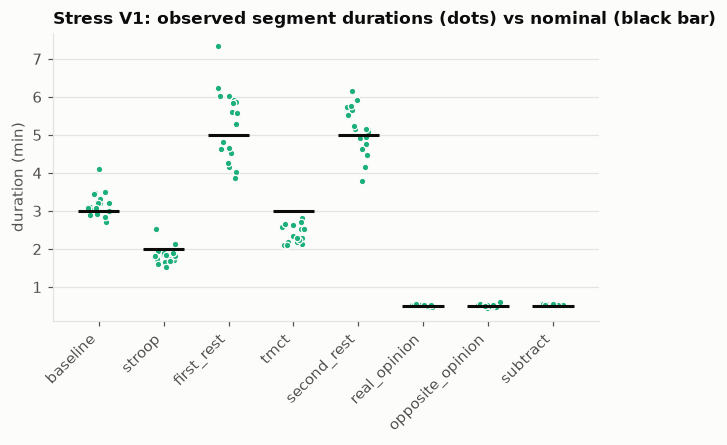

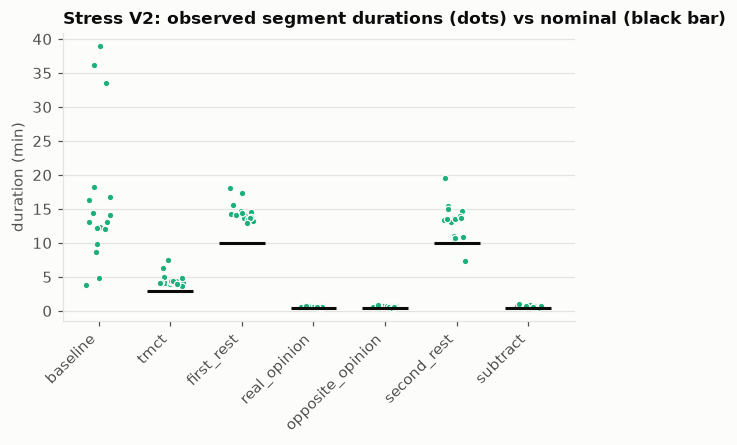

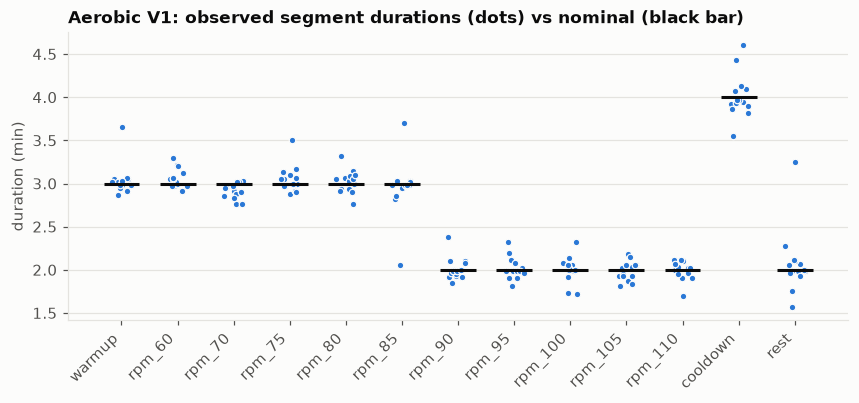

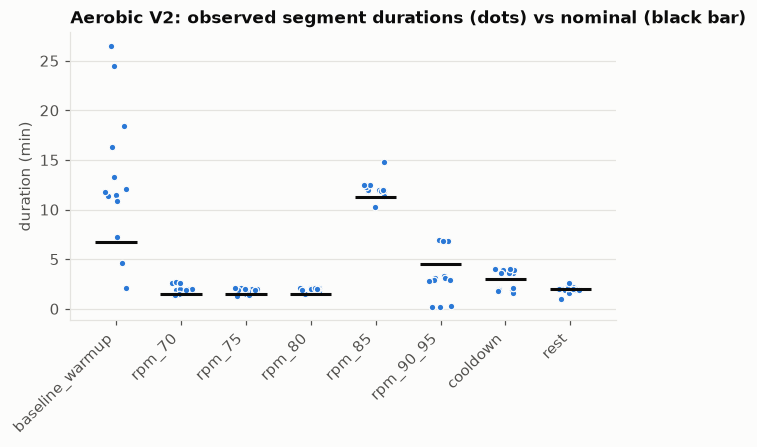

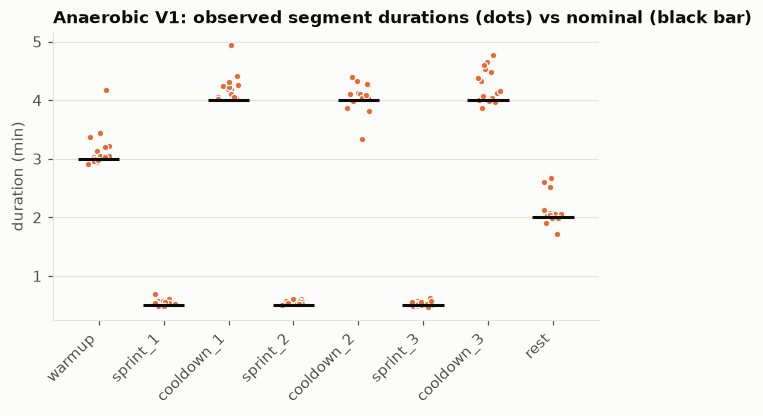

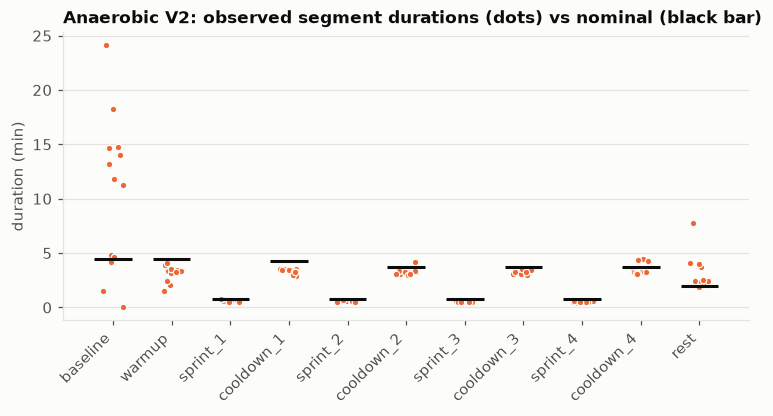

In [13]:
for cond, coh in [("STRESS", "V1"), ("STRESS", "V2"), ("AEROBIC", "V1"),
                  ("AEROBIC", "V2"), ("ANAEROBIC", "V1"), ("ANAEROBIC", "V2")]:
    fig = P.segment_durations(seg, cond, coh)
    P.save(fig, f"01_segment_durations_{cond.lower()}_{coh.lower()}"); plt.show()

In [14]:
dev = (seg[seg.map_source.eq("nominal") & seg.nominal_s.notna()]
       .groupby(["condition", "cohort", "segment"], sort=False)
       .agg(n=("duration_s", "size"), nominal_s=("nominal_s", "first"),
            median_s=("duration_s", "median"), min_s=("duration_s", "min"), max_s=("duration_s", "max"))
       .round(0))
dev

n nominal_s  median_s  min_s   max_s
condition cohort segment                                                
STRESS    V2     tmct              17     180.0     261.0  217.0   452.0
                 first_rest        17     600.0     853.0  778.0  1086.0
                 real_opinion      17      30.0      38.0   29.0    45.0
                 opposite_opinion  17      30.0      38.0   30.0    48.0
                 second_rest       17     600.0     807.0  439.0  1169.0
                 subtract          17      30.0      38.0   26.0    65.0
          V1     baseline          18     180.0     190.0  163.0   247.0
                 stroop            18     120.0     109.0   92.0   152.0
                 first_rest        18     300.0     326.0  232.0   440.0
                 tmct              18     180.0     137.0  125.0   169.0
                 second_rest       18     300.0     308.0  227.0   369.0
                 real_opinion      18      30.0      32.0   28.0    35.0
                 opposite_opinion  18      30.0      31.0   27.0    37.0
                 subtract          18      30.0      32.0   31.0    34.0
AEROBIC   V2     baseline_warmup   13     405.0     708.0  125.0  1592.0
                 rpm_70            13      90.0     119.0   84.0   164.0
                 rpm_75            13      90.0     113.0   75.0   125.0
                 rpm_80            13      90.0     120.0   87.0   125.0
                 rpm_85            13     675.0     717.0  615.0   890.0
                 rpm_90_95         13     270.0     176.0    9.0   415.0
                 cooldown          13     180.0     214.0   98.0   241.0
                 rest              13     120.0     120.0   60.0   157.0
          V1     warmup            14       180     180.0  172.0   219.0
                 rpm_60            14       180     182.0  175.0   198.0
                 rpm_70            14       180     176.0  166.0   182.0
                 rpm_75            14       180     182.0  173.0   210.0
                 rpm_80            14       180     182.0  166.0   199.0
                 rpm_85            14       180     179.0  123.0   222.0
                 rpm_90            14       120     119.0  111.0   143.0
                 rpm_95            14       120     119.0  109.0   139.0
                 rpm_100           14       120     120.0  103.0   139.0
                 rpm_105           14       120     119.0  109.0   131.0
                 rpm_110           14       120     121.0  102.0   127.0
                 cooldown          14       240     238.0  213.0   276.0
                 rest              14       120     120.0   94.0   195.0
ANAEROBIC V2     baseline          13     270.0     711.0    1.0  1446.0
                 warmup            13     270.0     200.0   88.0   243.0
                 sprint_1          13      45.0      36.0   28.0    45.0
                 cooldown_1        13     255.0     203.0  175.0   212.0
                 sprint_2          13      45.0      35.0   28.0    42.0
                 cooldown_2        13     225.0     197.0  180.0   249.0
                 sprint_3          13      45.0      31.0   28.0    42.0
                 cooldown_3        13     225.0     192.0  180.0   211.0
                 sprint_4          13      45.0      33.0   24.0    38.0
                 cooldown_4        13     225.0     196.0  187.0   265.0
                 rest              13     120.0     146.0  114.0   466.0
          V1     warmup            16       180     182.0  175.0   250.0
                 sprint_1          16        30      32.0   29.0    42.0
                 cooldown_1        16       240     251.0  241.0   296.0
                 sprint_2          16        30      32.0   30.0    36.0
                 cooldown_2        16       240     245.0  200.0   264.0
                 sprint_3          16        30      31.0   28.0    37.0
                 cooldown_3        16       240     248.0  232.0   286.0
                 rest

Observed durations deviate from the plan. This matters for feature engineering: windows must be cut from the
**tags**, never from nominal times.
- V2 "45-s" sprints actually last a median **31–36 s** (tag-to-tag).
- V2 stress rests are ~13–14 min (nominal 10). V2 TMCT is ~4.3 min (nominal 3). V1 TMCT is ~2.3 min.
- The time before the first tag (pre-protocol baseline) ranges from seconds to ~39 min.

**V2 exercise happened in group sessions.** The de-identified session dates and start times cluster into
groups, and the aerobic tag timing differs systematically between them:

In [15]:
v2 = sessions[(sessions.cohort == "V2") & (sessions.condition != "STRESS")].copy()
v2["start"] = [load_session(r.condition, r.session_id).signals["EDA"].start for r in v2.itertuples()]
v2["group_session"] = v2.groupby("condition").start.transform(
    lambda s: (s.sort_values().diff() > pd.Timedelta("30min")).cumsum().reindex(s.index))
v2 = v2.merge(tags[["condition", "session_id", "tag_intervals_s"]])
v2.sort_values(["condition", "start"])[["condition", "group_session", "session_id", "start", "tag_intervals_s"]]

,condition,group_session,session_id,start,tag_intervals_s
4,AEROBIC,0,f05,2013-06-20 11:52:28+00:00,"87,91,87,890,15,112,98"
5,AEROBIC,0,f06,2013-06-20 11:57:44+00:00,"84,75,106,710,9,111,60"
6,AEROBIC,0,f07,2013-06-20 12:03:54+00:00,"84,86,125,694,-12,110,132"
3,AEROBIC,1,f04,2013-06-20 12:55:45+00:00,"157,122,120,735,409,120,116"
9,AEROBIC,1,f10,2013-06-20 12:56:14+00:00,"156,112,115,751,413,107,114"
8,AEROBIC,1,f09,2013-06-20 12:56:39+00:00,"164,106,120,750,415,126,119"
2,AEROBIC,2,f03,2013-07-04 12:06:30+00:00,"119,115,124,717,198,214,122"
0,AEROBIC,2,f01,2013-07-04 12:06:34+00:00,"122,113,125,715,189,219,122"
11,AEROBIC,2,f12,2013-07-04 12:11:02+00:00,"122,113,124,715,188,214,113"
12,AEROBIC,3,f13,2013-07-04 13:09:26+00:00,"114,122,120,718,176,241,120"


Aerobic V2 group 0 (f05, f06, f07) effectively **skipped the 90/95-rpm stage** (tags 5 and 6 pressed 9–15 s apart,
and out of order in f07). Group 1 (f04, f09, f10) held it for ~7 min instead of 4:30. Participants who trained
together share instructor timing, room conditions and a social context. That is a clustering factor for Phase 2.

## 7 · Missing data

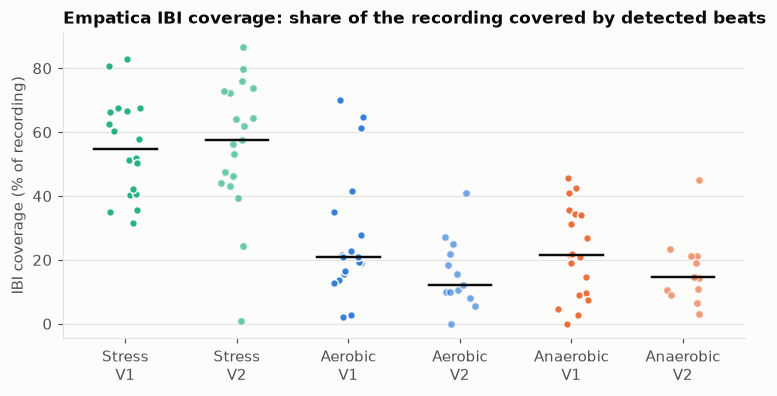

,ibi_coverage_pct,n_gaps_gt3s,longest_gap_s
condition,,,
AEROBIC,19.0,81.0,100.2
ANAEROBIC,19.0,51.0,118.5
STRESS,57.7,69.0,54.7


In [16]:
cov = ibi.merge(sessions[["condition", "session_id", "cohort"]])
fig = P.strip_by_condition(cov, "ibi_coverage_pct", "IBI coverage (% of recording)",
                           "Empatica IBI coverage: share of the recording covered by detected beats")
P.save(fig, "01_ibi_coverage"); plt.show()
cov.groupby("condition")[["ibi_coverage_pct", "n_gaps_gt3s", "longest_gap_s"]].median().round(1)

Empatica only exports an IBI when it trusts the beat, so IBI coverage is a direct readout of PPG quality.
Coverage is **~58% during the seated stress protocol but ~19% during cycling**, with gaps of up to 23 min. This is
why the authors themselves did not use `IBI.csv`. HRV from E4 IBI is only defensible in selected low-motion segments
that meet a coverage threshold, and even then RMSSD is affected by the 15.6-ms quantisation.

In [17]:
q = quality.pivot_table(index=["condition", "session_id"], columns="signal",
                        values=["pct_eda_below_0.05uS", "pct_temp_below_30C", "pct_saturated",
                                "pct_bvp_exact_zero", "longest_flat_s"], aggfunc="first")
flags = pd.DataFrame({
    "EDA <0.05 µS >5% of time": q[("pct_eda_below_0.05uS", "EDA")] > 5,
    "TEMP <30 °C >20% of time": q[("pct_temp_below_30C", "TEMP")] > 20,
    "TEMP >45 °C (fault code)": quality[quality.signal == "TEMP"].set_index(["condition", "session_id"])["max"] > 45,
    "ACC saturated >1%": q[("pct_saturated", "ACC")] > 1,
    "BVP exact-zero >1%": q[("pct_bvp_exact_zero", "BVP")] > 1,
    "EDA flat >10 s": q[("longest_flat_s", "EDA")] > 10,
})
print("Sessions flagged per check:"); print(flags.sum().to_string())
flags[flags.any(axis=1)].replace({True: "x", False: ""})

Sessions flagged per check:
EDA <0.05 µS >5% of time     7
TEMP <30 °C >20% of time    13
TEMP >45 °C (fault code)     4
ACC saturated >1%            1
BVP exact-zero >1%           1
EDA flat >10 s               6


EDA <0.05 µS >5% of time TEMP <30 °C >20% of time TEMP >45 °C (fault code) ACC saturated >1% BVP exact-zero >1% EDA flat >10 s
condition session_id                                                                                                                               
AEROBIC   S04                                                                                                                                     x
          S07                                                                                 x                                                    
          S09                                                        x                        x                                                    
          f01                               x                                                                                                      
          f02                               x                                                                                                     x
          f04                                                                                                                      x               
          f08                               x                        x                                                                             
          f09                                                        x                                                                             
          f13                                                                                                                                     x
ANAEROBIC S02                                                                                 x                                                    
          S05                                                                                 x                                                    
          S07                                                        x                                                                             
          S08                               x                                                                                                     x
          S09                                                                                                                                     x
          S12                                                        x                                                                             
          S14                                                        x                                                                             
          f05                                                        x                                                                             
          f07                                                        x                                                                             
          f08                               x                                                                                                      
          f09                                                                                                   x                                  
          f10                                                        x                                                                             
STRESS    f05                                                        x                                                                             
          f07                                                        x                                                                             
          f08                                                        x                                                                             
          f12                               x                                                                                                      
          f13            

## 8 · Signal-quality red flags

### 8.1 Duplicated export (STRESS/S02)
A brute-force search for the first 30 s of each signal re-appearing later in the same file finds the documented
duplication, and nothing else, across all 100 sessions:

In [18]:
quality[quality.repeat_at_sample.notna()][["condition", "session_id", "signal", "n_samples", "repeat_at_sample"]]

,condition,session_id,signal,n_samples,repeat_at_sample
100,STRESS,S02,ACC,99084,49542.0
101,STRESS,S02,BVP,198176,99088.0
102,STRESS,S02,EDA,12384,6192.0
104,STRESS,S02,TEMP,12384,6192.0


### 8.2 Skin temperature: fault codes and equilibration
Four sessions contain non-physical TEMP values (207–235 °C, a sensor fault code). These are **not** listed in
`data_constraints.txt`. In the seated stress protocol most sessions are stable from the first minute, but a few
start cold (24–28 °C) and climb slowly for 10–20 min, which looks like the band warming to the skin. Short
drop-outs to ~28 °C also appear. On the bike, TEMP becomes much noisier (see the anaerobic overview in §9),
consistent with intermittent sensor contact, airflow and sweat. Absolute skin temperature is therefore weak
evidence. Within-session change in clean segments is the better use.

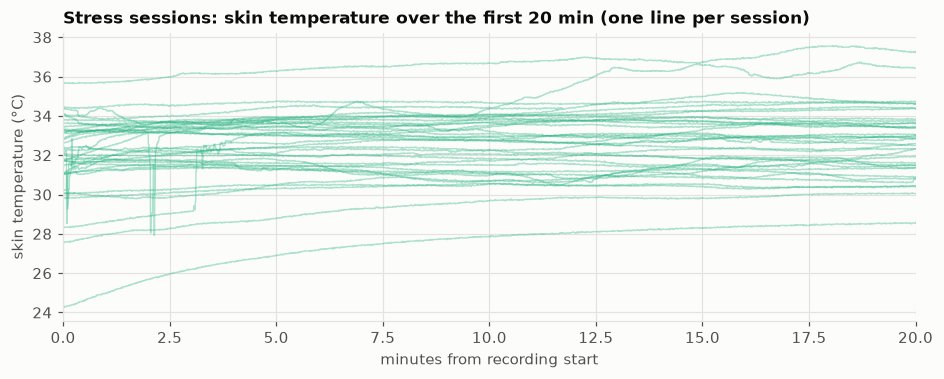

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for r in sessions[sessions.condition == "STRESS"].itertuples():
    s = load_session(r.condition, r.session_id).signals["TEMP"]
    y = s.data.TEMP.where(s.data.TEMP < 45)
    ax.plot(s.data.index / 60, y, color=P.COND_COLORS["STRESS"], alpha=0.35, lw=0.9)
ax.set_xlim(0, 20); ax.set_xlabel("minutes from recording start"); ax.set_ylabel("skin temperature (°C)")
ax.set_title("Stress sessions: skin temperature over the first 20 min (one line per session)", loc="left")
P.save(fig, "01_temp_equilibration"); plt.show()

### 8.3 Empatica HR during cycling is frequently implausible
During an incremental test (aerobic V1: 60 → 110 rpm with resistance rising to 50% of maximum), HR should
rise roughly monotonically with workload. Mean E4 HR per stage:

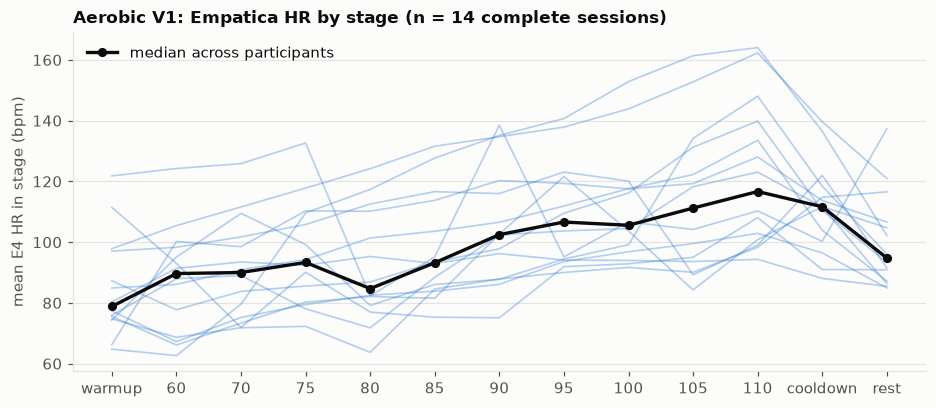

Spearman rho (rpm stage vs HR) per session:
session_id
S07     -0.61
S13     -0.26
S01      0.12
S14      0.35
S06      0.54
S15      0.55
S18      0.79
S08      0.85
S10      0.87
S09      0.92
S11_a    0.98
S03      1.00
S05      1.00
S02      1.00
S16      1.00
S04      1.00
S17      1.00


In [20]:
hr_rows = []
for (c, s), g in seg.groupby(["condition", "session_id"]):
    sess = load_session(c, s)
    hr = sess.signals["HR"]; off = (hr.start - sess.signals["EDA"].start).total_seconds()
    tt = hr.data.index.values + off; v = hr.data.HR.values
    for r in g.itertuples():
        m = (tt >= r.start_s) & (tt < r.end_s)
        hr_rows.append(dict(condition=c, cohort=r.cohort, session_id=s, segment=r.segment,
                            phase=r.phase, hr=np.nanmean(v[m]) if m.any() else np.nan))
hr_seg = pd.DataFrame(hr_rows); hr_seg.to_csv(INTERIM / "hr_by_segment_e4.csv", index=False)

stages = ["warmup"] + [f"rpm_{r}" for r in [60, 70, 75, 80, 85, 90, 95, 100, 105, 110]] + ["cooldown", "rest"]
a1 = hr_seg[(hr_seg.condition == "AEROBIC") & (hr_seg.cohort == "V1") & hr_seg.segment.isin(stages)]
complete = a1.groupby("session_id").segment.nunique().loc[lambda s: s == len(stages)].index
fig = P.hr_by_stage(a1[a1.session_id.isin(complete)], stages,
                    f"Aerobic V1: Empatica HR by stage (n = {len(complete)} complete sessions)")
P.save(fig, "01_hr_by_stage_aerobic_v1"); plt.show()

from scipy.stats import spearmanr
rho = (a1[a1.segment.str.startswith("rpm")]
       .assign(rpm=lambda d: d.segment.str.extract(r"(\d+)").astype(float)[0])
       .groupby("session_id").apply(lambda d: spearmanr(d.rpm, d.hr).statistic, include_groups=False))
print("Spearman rho (rpm stage vs HR) per session:"); print(rho.round(2).sort_values().to_string())

Three patterns appear:
1. **Expected staircase with plausible magnitude** (e.g. S02, S04 up to ~160–165 bpm at 110 rpm).
2. **Monotonic but implausibly low**: S17 and S11_a are perfectly ordered (ρ ≈ 1) yet peak at only ~100 bpm at
   105–110 rpm.
3. **Flat or erratic**: S15 sits at ~94 bpm from 60 to 110 rpm. S01, S13 and S07 have ρ ≤ 0.12, with sudden drops
   (e.g. S01: 120 → 89 bpm between 100 and 105 rpm).

Absolute power output (watts) was not recorded, so the expected HR cannot be calculated. Even so, ~100 bpm in
healthy 19–22-year-old men at the hardest stage of a maximal-type protocol is hard to reconcile with exercise
physiology. **Monotonicity alone is not a sufficient quality check.**

A plausible mechanism is **PPG motion artefact**: gripping the handlebars and rhythmic forearm loading
corrupt the wrist PPG. Because cadence is prescribed, we can check whether the PPG locked onto the pedalling rhythm:

In [21]:
from scipy.signal import welch, butter, filtfilt
from src.data.empatica import acc_magnitude_g

def dominant_per_min(x, fs, lo=0.7, hi=3.7):
    b, a = butter(3, [lo / (fs / 2), hi / (fs / 2)], "band")
    y = filtfilt(b, a, x - np.mean(x))
    f, p = welch(y, fs=fs, nperseg=min(len(y), int(fs * 30)))
    m = (f >= lo) & (f <= hi)
    return f[m][np.argmax(p[m])] * 60

rows = []
for s, g in seg[(seg.condition == "AEROBIC") & (seg.cohort == "V1") & seg.segment.str.match(r"rpm_\d+$")].groupby("session_id"):
    sess = load_session("AEROBIC", s)
    for r in g.itertuples():
        a, b = r.start_s + 10, r.end_s - 10          # trim transitions between stages
        rpm = int(r.segment.split("_")[1])
        bvp = sess.signals["BVP"].data.BVP.loc[a:b].values
        acc = acc_magnitude_g(sess.signals["ACC"].data.loc[a:b]).values
        hr_mean = hr_seg.query("condition=='AEROBIC' and session_id==@s and segment==@r.segment").hr.iloc[0]
        rows.append(dict(session_id=s, rpm=rpm, hr_e4=hr_mean,
                         bvp_dominant=dominant_per_min(bvp, 64), acc_dominant=dominant_per_min(acc, 32)))
lock = pd.DataFrame(rows)
lock["acc_over_rpm"] = lock.acc_dominant / lock.rpm
lock["bvp_at_cadence"] = ((lock.bvp_dominant - lock.rpm).abs() <= 4) | ((lock.bvp_dominant - 2 * lock.rpm).abs() <= 6)
lock["hr_at_cadence"] = (lock.hr_e4 - lock.rpm).abs() <= 5
lock.to_csv(INTERIM / "cadence_lockin_aerobic_v1.csv", index=False)
print(f"{len(lock)} stage-segments")
print(f"Median ACC dominant frequency / prescribed rpm: {lock.acc_over_rpm.median():.2f}  (≈2 = one wrist oscillation per foot-down)")
print(f"BVP dominant frequency at cadence or 2×cadence: {lock.bvp_at_cadence.mean():.0%}")
print(f"E4 HR within ±5 bpm of cadence: {lock.hr_at_cadence.mean():.0%}")

161 stage-segments
Median ACC dominant frequency / prescribed rpm: 1.94  (≈2 = one wrist oscillation per foot-down)
BVP dominant frequency at cadence or 2×cadence: 22%
E4 HR within ±5 bpm of cadence: 22%


- The accelerometer's dominant frequency is ≈2× the prescribed rpm (one wrist oscillation per foot-down,
  matching the metronome instructions). **ACC independently confirms the protocol cadence.**
- In roughly a quarter of stages, HR or the PPG's dominant frequency sits on the cadence. That is consistent with
  motion contamination, but it does not explain all the failures. **Empatica HR during exercise cannot be used
  without a per-segment quality assessment.** This is the main task for Phase 2.

## 9 · Multimodal overview: one participant, three conditions

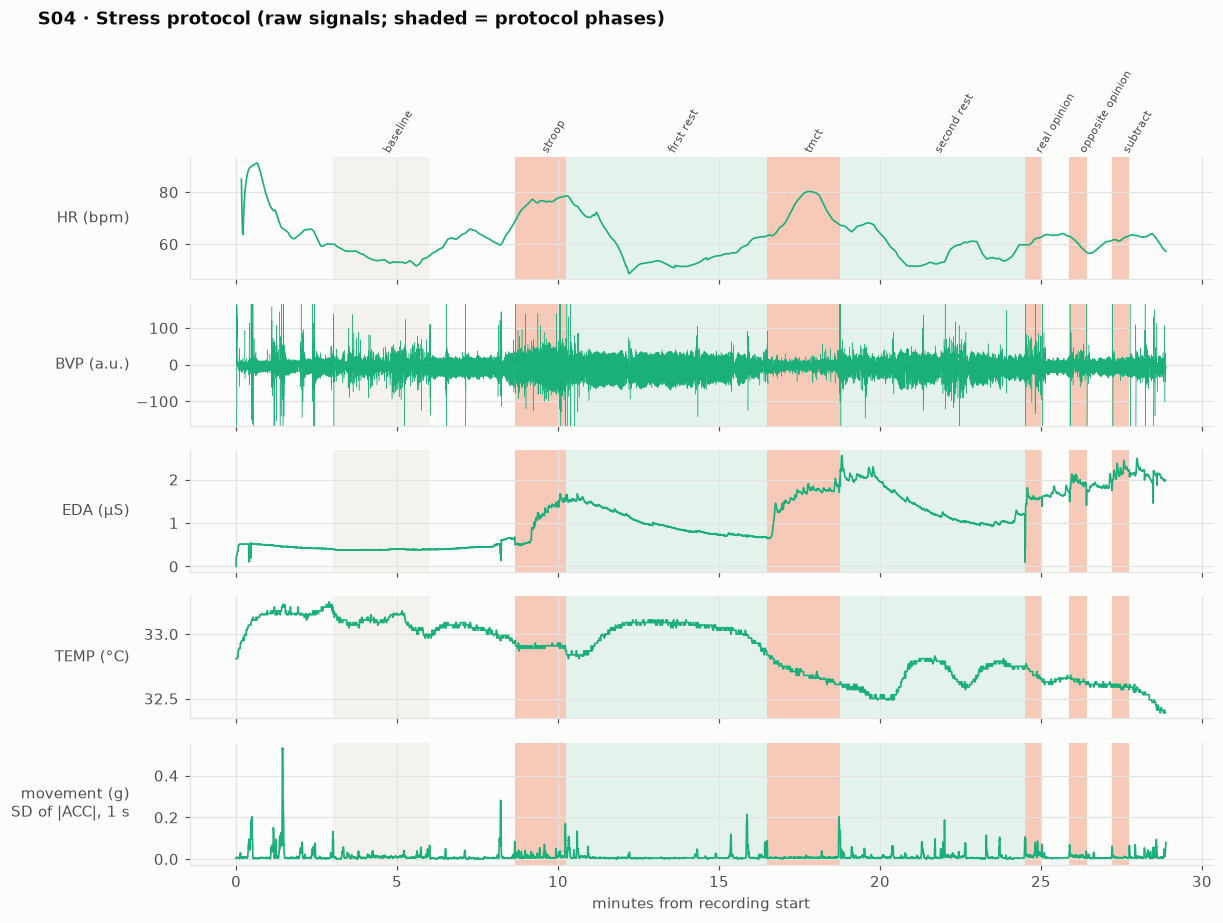

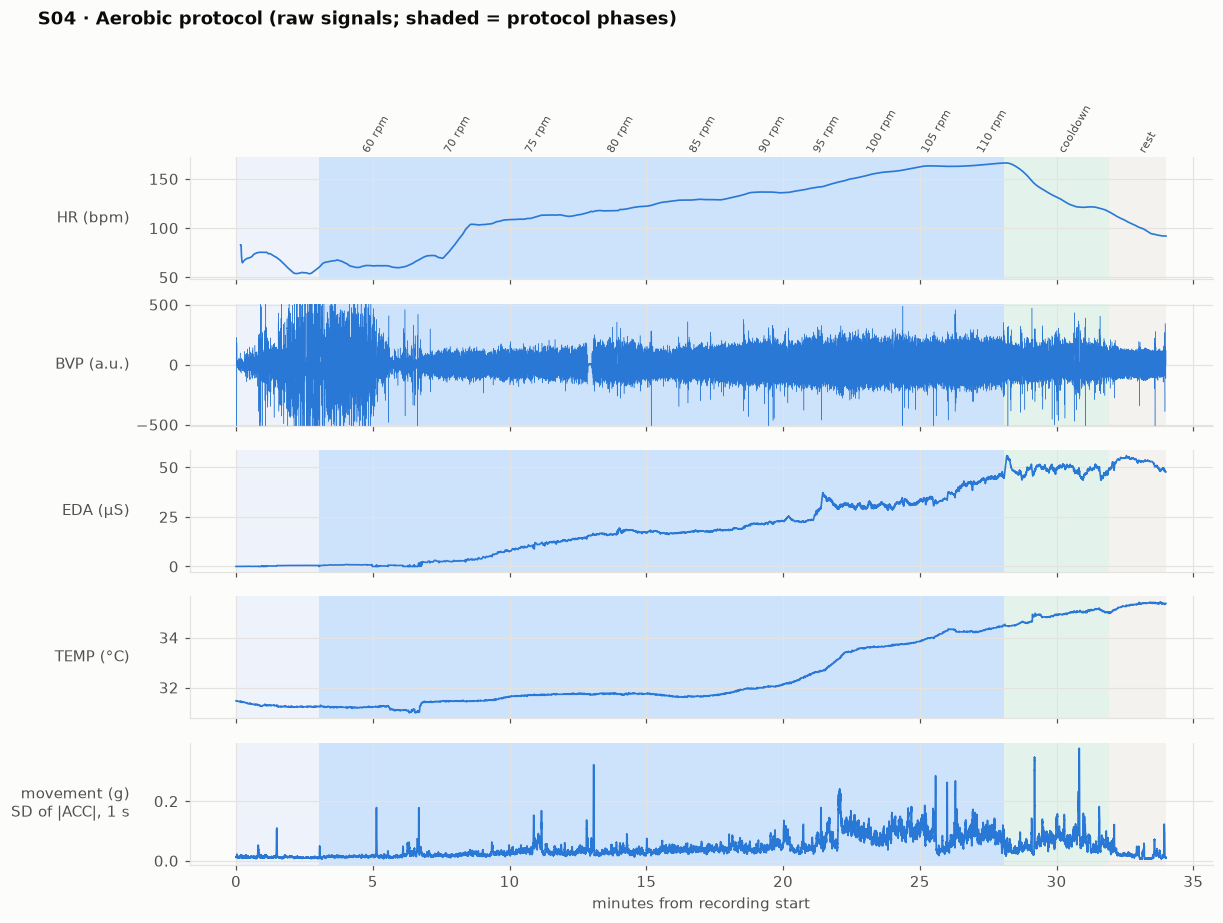

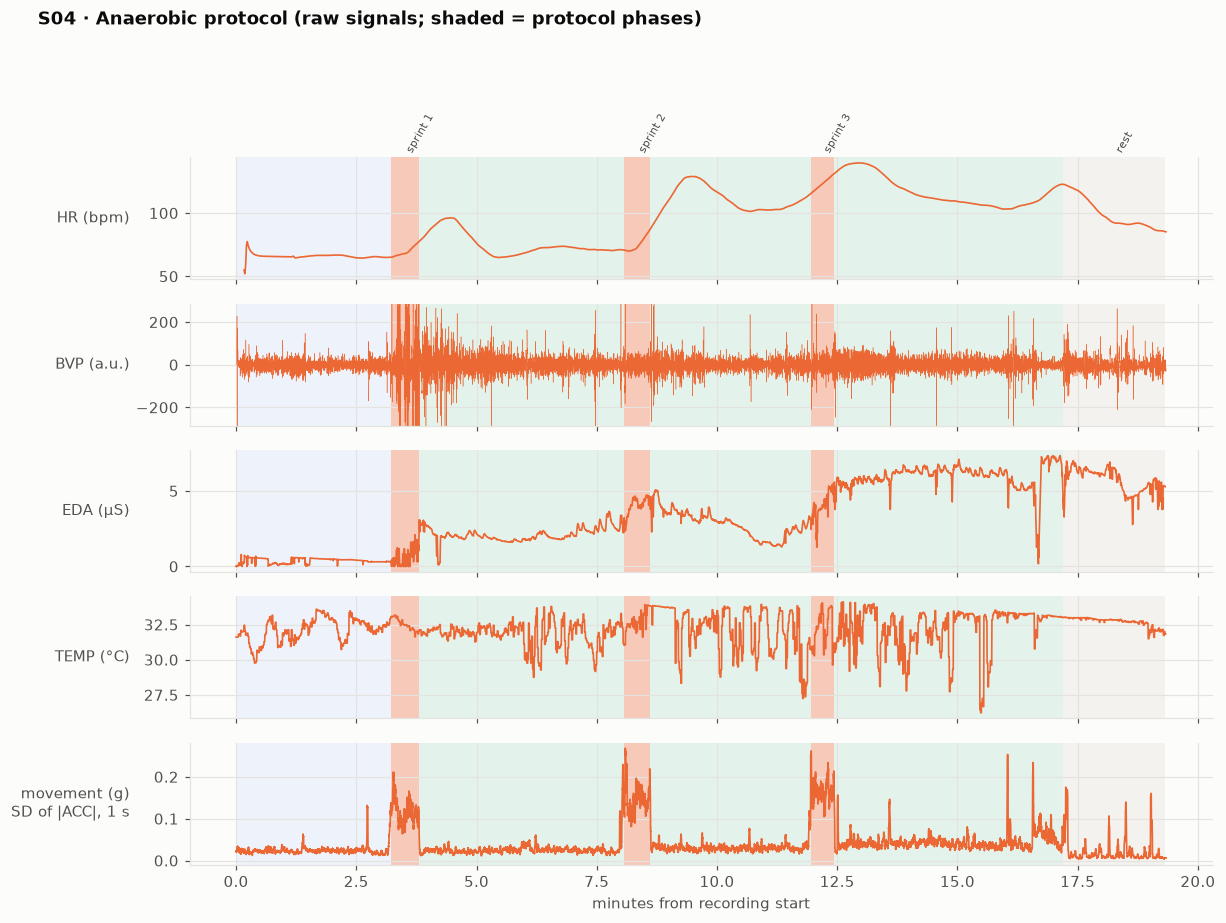

In [22]:
for cond in ["STRESS", "AEROBIC", "ANAEROBIC"]:
    sess = load_session(cond, "S04")
    fig = P.session_overview(sess, seg[(seg.condition == cond) & (seg.session_id == "S04")],
                             title=f"S04 · {cond.title()} protocol (raw signals; shaded = protocol phases)")
    P.save(fig, f"01_overview_S04_{cond.lower()}"); plt.show()

Reading these panels as a physiotherapist (one participant, so illustrative only):
- **Stress:** HR rises by ~20–25 bpm during Stroop and TMCT, and EDA jumps at task onset then decays through each
  rest. Wrist movement is essentially zero. **A clear physiological response with no movement**: the core reason
  ACC alone cannot describe physiological state.
- **Aerobic:** HR climbs steadily from ~60 to ~165 bpm and falls quickly in cooldown and rest. EDA rises from <1 to
  ~50 µS (sweating). Skin temperature *rises* late in the test. Wrist movement rises with cadence (~0.01 → 0.1 g)
  but stays small, because the hands rest on the handlebars. ACC tracks cadence, not the leg work or resistance.
- **Anaerobic:** each sprint is a short, large movement burst. E4 HR peaks ~1 min *after* the sprint ends. Part of
  that is genuine HR kinetics, but part may be Empatica's smoothing and artefact rejection. EDA steps up with each
  sprint and stays raised. TEMP is very noisy during cooldowns.
- EDA rises in both stress and exercise, at very different magnitudes (~2 µS vs ~50 µS here). EDA alone is
  ambiguous without movement and HR context.

## 10 · Self-reported stress (context)

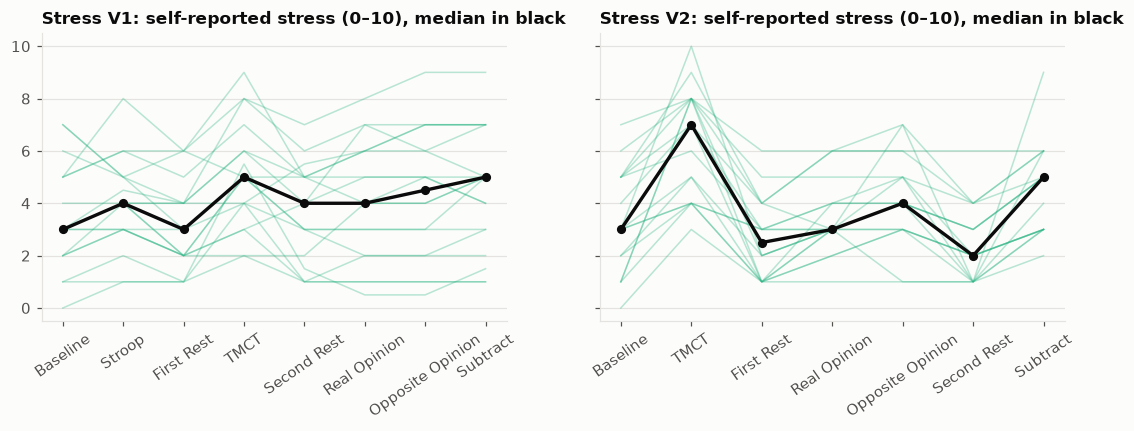

Scale minimum observed: 0.0 (paper describes a 1–10 scale)


In [23]:
sl = read_stress_levels()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, (v, d) in zip(axes, sl.items()):
    for _, row in d.iterrows():
        ax.plot(d.columns, row.values, color=P.COND_COLORS["STRESS"], alpha=0.3, lw=1)
    ax.plot(d.columns, d.median().values, color=P.TEXT, lw=2.2, marker="o", ms=5)
    ax.set_title(f"Stress {v}: self-reported stress (0–10), median in black", loc="left")
    ax.tick_params(axis="x", rotation=35); ax.grid(axis="x", visible=False)
P.save(fig, "01_self_reported_stress"); plt.show()
print("Scale minimum observed:", min(d.min().min() for d in sl.values()), "(paper describes a 1–10 scale)")

## 11 · Issue registry

In [24]:
iss = issues_table(); iss.to_csv(INTERIM / "known_issues.csv", index=False)
print(iss.source.value_counts().to_string())
iss[["source", "condition", "session_id", "signals", "issue"]]

source
phase1                  15
data_constraints.txt    10


,source,condition,session_id,signals,issue
0,data_constraints.txt,STRESS,S02,ALL,E4 Connect export duplicated: second half of A...
1,data_constraints.txt,STRESS,f07,"BVP,HR,IBI,TEMP",Protective dock left on: PPG and temperature s...
2,data_constraints.txt,STRESS,f14_a/f14_b,ALL,"Bluetooth loss: baseline in f14_a (no tags), r..."
3,data_constraints.txt,AEROBIC,S03,ALL,Ended early; tags cover 60-85 rpm only (constr...
4,data_constraints.txt,AEROBIC,S07,ALL,Ended early after 95 rpm.
5,data_constraints.txt,AEROBIC,S11_a/S11_b,ALL,Bluetooth loss during 110 rpm; S11_b content i...
6,data_constraints.txt,AEROBIC,S12,ALL,Did not perform the aerobic protocol (no folder).
7,data_constraints.txt,ANAEROBIC,S01,IBI,IBI.csv is empty.
8,data_constraints.txt,ANAEROBIC,S06,ALL,Last (3rd) sprint missing.
9,data_constraints.txt,ANAEROBIC,S16_a/S16_b,ALL,"Bluetooth loss: sprints 1-2 in S16_a, sprints ..."


## 12 · Summary

| Topic | Finding |
|---|---|
| Integrity | 707/707 files match the v1.0.1 SHA-256 manifest |
| Sessions | 100 recordings: 37 stress, 31 aerobic, 32 anaerobic (incl. 3 split pairs) |
| Participants | 36 (stress), 30 (aerobic), 31 (anaerobic). 30 have all three protocols |
| Confounding | Cohort = sex = protocol version (V1: 18 M; V2: 17 F + 1 M) |
| Sampling rates | ACC 32 Hz, BVP 64 Hz, EDA 4 Hz, TEMP 4 Hz, HR 1 Hz, IBI event-based. All headers match the documentation |
| Synchronisation | Common start timestamp; HR starts +10 s; ends differ ≤ 7.5 s |
| Tags | 6 protocol variants. Stress V1 has 13 tags (diagram says 12). 1 file with tags out of order; 1 empty tag file |
| Baselines | No seated baseline in V1 exercise sessions |
| IBI | Coverage ~58% (stress) vs ~19% (exercise). Quantised to 15.6 ms |
| HR | Often implausible during cycling. Must be quality-checked per segment |
| New issues | 15 issues not listed in `data_constraints.txt` (TEMP fault codes, stuck ACC axis, flat PPG, tag order, …) |

Next: `02_signal_quality.ipynb` (Phase 2).